# Task 1

In [41]:
import random
import numpy as np
import matplotlib.pyplot as plt

SEED = 22040 # Fixed number for the RNG to ensure reproducability.
random.seed(SEED)
np.random.seed(SEED)


### Conversion functions

Integer values are encoded as 6-bit binary strings (represented as a list) e.g., [0, 0, 0, 0, 1, 1] is 3. Values encoded as integers range from 0 to 63.

**Phenotype:** Integer value (e.g., 17)

**Genotype:** 6-bit binary string (e.g., [0, 0, 1, 0, 1, 0]).

In [42]:
def geno_to_pheno(individuals):
    "Returns a list of the integer values corresponding to their the 6-bit binary value."
    return [int("".join(map(str, individual)), 2) for individual in individuals]

def pheno_to_geno(x_values):
    "Returns a 6-bit binary string encoded as a list of integers."
    return [[int(bit) for bit in format(x_value, '06b')] for x_value in x_values]

### Initialization Function: (Inputs: Population Size; Output: Individuals). 

In [43]:
def initialization_population( pop_size: int, num_bits: int=6  ) -> list[list[int]]:
    """
    This function creates the individuals for the population, each having six binary genes. 

    It returns the individuals as a list of lists e.g., [[0, 1, 1, 0, 1,0], [0, 1, 1, 1, 1,1]].
    """
    population = []
    for _ in range(pop_size):
        population.append(np.random.randint(0, 2, num_bits, int).tolist()) # individual (6-bit binary string)
    return population

### Initalization Subtask 

Generates 4 individuals and prints out each individual and their type (Genotype).

In [44]:
def initialize_population_subtask():
    individuals_geno = initialization_population(4, 6)

    print("Individuals Generated (Genotype):")
    for num, individual in enumerate(individuals_geno):
        print(f"{num + 1}: {individual}")

initialize_population_subtask()

Individuals Generated (Genotype):
1: [1, 0, 0, 1, 0, 0]
2: [1, 0, 1, 0, 0, 1]
3: [1, 1, 1, 1, 1, 1]
4: [1, 1, 1, 0, 0, 0]


### Fitness Function: (Inputs: Individuals; Output: Fitness values). 

In [45]:
def fitness( individuals: list[list[int]] ) -> list[float]:
    """
    Takes as input one or multiple individuals (genotype), converts them to their integer value (phenotype), 
    and returns a list the resulting fitness values for all of them.
    """
    coeffs_exps_pairs = [
        (-0.00008333, 6),
        (-0.001, 5),
        (0.09375, 4),
        (1.16667, 3),
        (-19.53125, 2),
        (-234.375, 1),
        (8350, 0)
    ]

    def evaluate( value: float ) -> float:
        y_val = value - 64 if value >= 32 else value 
        return sum(
                coeff * y_val**exp
                for coeff, exp in coeffs_exps_pairs
        )

    return [evaluate(value) for value in geno_to_pheno(individuals)]

### Fitness Subtask

Individual (Geno)  | Expected Fitness | Actual Fitness 
-------------------|------------------|---------------
[0, 1, 0, 1, 0, 1] | 12_620.97        | 12_620.976507

Fitness value within range: [12_620,12_621]

Plotting distribution of fitness values for all possible phenotype values (0 - 63):


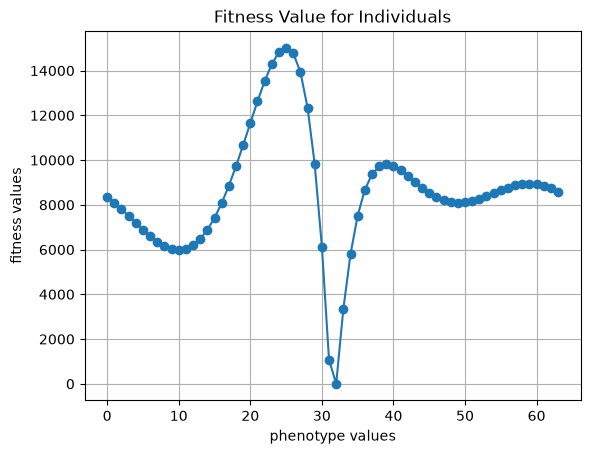

X values corresponding to minimum/maximum fitness:

X value (pheno) | Fitness Value
----------------|--------------
32              | 4.0832461
25              | 15024.0429688


In [46]:
def fitness_subtask( individual: list[list[int]], samples: int ):
    """
    Checks for the individual = [[0, 1, 0, 1, 0, 1]] that their fitness value is approximately 12620.97.

    Plots the fitness landscape (x-axis: integer values (phenotype); y-axis: fitness) for all possible integer values.
    """
    expected = 12_620.97
    fitness_value = fitness(individual)

    print(f"Individual (Geno){"":<1} | Expected Fitness | Actual Fitness ")
    print("-" * 19 + "|" + "-" * 18 + "|" + "-" * 15)
    print(f"{individual[0]} | {expected:_} {"":<6} | {fitness_value[0]:_.6f}\n")

    if 12_620 <= fitness_value[0] <= 12_621:
        print(f"Fitness value within range: [{12_620:_},{12_621:_}]\n")
    else:
        print(f"Fitness value not within range: [{12_620:_},{12_621:_}]\n")

    print("Plotting distribution of fitness values for all possible phenotype values (0 - 63):")
    x_vals = list(range(samples))
    fitness_values = fitness(pheno_to_geno(x_vals))

    x_min = np.argmin(fitness_values)
    x_max = np.argmax(fitness_values)

    plt.plot(x_vals, fitness_values, marker='o')
    plt.title("Fitness Value for Individuals")
    plt.xlabel("phenotype values")
    plt.ylabel("fitness values")
    plt.grid(True)
    plt.show()

    print("X values corresponding to minimum/maximum fitness:\n")
    print("X value (pheno) | Fitness Value")
    print("-" * 16 + "|" + "-" * 14)    
    print(f"{x_min:<15} | {fitness_values[x_min]:.7f}")
    print(f"{x_max:<15} | {fitness_values[x_max]:.7f}")

fitness_subtask([[0, 1, 0, 1, 0, 1]], 64)

In [47]:

def generate_population_and_fitness_values( samples: int=64 ) -> tuple[list[int], list[float], float, float]:
    """ Helper function to generate N samples and their fitness values. 

    Returns individuals (pheno), fitness values, and the individuals that correspond to the min/max fitness values.
    """
    x_values = list(range(samples))
    fitness_values = fitness(pheno_to_geno(x_values))
    x_min = np.argmin(fitness_values)
    x_max = np.argmax(fitness_values)
    return x_values, fitness_values, x_min, x_max


### Parent Selection Function: (Inputs: Individuals, Fitness values; Output: Parents (in random order, same number as individuals)). 

In [48]:
def parent_selection( individuals: list[list[int]], fitness_values: list[float] ) -> list[list[int]]:
    """Perform fitness-proportional parent selection such that more fit parents have a higher probability to be selected. """
    fitness = np.array(fitness_values, dtype=float)
    probs = fitness / fitness.sum()
    idx = np.random.choice(len(individuals), size=len(individuals), replace=True, p=probs)
    return [individuals[i] for i in idx]

### Testing Parent Selection

In [49]:
def parent_selection_iterations( x_values: list[int], fit_vals: list[float], num_iter: int=1,  require_max_most: bool=False ) -> list[list[int]]:
    "Performs N iterations on the parent selection process, printing the selection rate/count for each parent."
    x_vals_geno = pheno_to_geno(x_values)
    counts = { val : 0 for val in x_values }
    x_max = x_values[np.argmax(fit_vals)]
    n, attempts = num_iter, 0

    while n > 0:
        attempts += 1
        parents = parent_selection(x_vals_geno, fit_vals)
        run_counts = {val: 0 for val in x_values}
        for p in geno_to_pheno(parents):
            run_counts[p] += 1

        # For single-iteration we employ discriminatory parent selecting,
        # i.e. selecting the run where x_max is counted the most.
        if require_max_most and run_counts[x_max] < max(run_counts.values()):
            continue  # reject this run, nothing added to totals

        for val, c in run_counts.items():
            counts[val] += c
        n -= 1

    if require_max_most:
        print(f"Accepted run after {attempts} attempt(s)")

    for individual, fitness_val, x_val in zip(x_vals_geno, fit_vals, x_values):
        rate = counts[x_val] / (num_iter * len(x_values)) * 100
        last_field = (
            f"Selection Rate: {rate:.4f}%"
            if num_iter > 10
            else f"Selected: {counts[x_val]}x"
        )

        print(
            f"Individual: {str(individual)}, {str(x_val):<5} "
            f"Fitness: {fitness_val:<12.4f} "
            f"{last_field}"
        )

    return parents


def parent_selection_subtask():
    """
    Provides parent_selection four individuals to perform on: 
        1. The one leading to minimum fitness, 
        2. to maximum fitness, 
        3. and two more individuals of moderate fitness. 
    
    First run of the parent_selection it looks for a run where highest-fit is selected the most.
    Second run performs 10,000, indisciminatory iterations and gives the selection rate.  
    """
    # Selects test subjects (x values) based on their fitness level (min, medium, medium, max)
    _, fitness_vals, x_min, x_max = generate_population_and_fitness_values(samples=64)
    
    mid_fit = (fitness_vals[x_min] + fitness_vals[x_max]) / 2
    closest = np.argsort(np.abs(np.array(fitness_vals) - mid_fit))
    x_mod1, x_mod2 = closest[0], closest[1]

    x_values = [x_min, x_mod1, x_mod2, x_max]
    fit_vals = [
        fitness_vals[x_min],
        fitness_vals[x_mod1],
        fitness_vals[x_mod2],
        fitness_vals[x_max]
    ]

    # Single iteration parent_selection run for the x values
    print("Single parent selection run: ")

    parents = parent_selection_iterations(x_values, fit_vals, require_max_most=True)
    print(f"Parents Selected: {parents}\n")

    # Multiple iteration parent_selection runs for x values, highlighting selection rate
    num_iter = 10_000
    print(f"\nMultiple parent selection run ({num_iter:_} iterations):" )
    parents = parent_selection_iterations(x_values, fit_vals, num_iter)


parent_selection_subtask()

Single parent selection run: 
Accepted run after 1 attempt(s)
Individual: [1, 0, 0, 0, 0, 0], 32    Fitness: 4.0832       Selected: 0x
Individual: [0, 0, 0, 0, 1, 1], 3     Fitness: 7509.8838    Selected: 1x
Individual: [1, 0, 0, 0, 1, 1], 35    Fitness: 7519.2945    Selected: 0x
Individual: [0, 1, 1, 0, 0, 1], 25    Fitness: 15024.0430   Selected: 3x
Parents Selected: [[0, 1, 1, 0, 0, 1], [0, 1, 1, 0, 0, 1], [0, 0, 0, 0, 1, 1], [0, 1, 1, 0, 0, 1]]


Multiple parent selection run (10_000 iterations):
Individual: [1, 0, 0, 0, 0, 0], 32    Fitness: 4.0832       Selection Rate: 0.0200%
Individual: [0, 0, 0, 0, 1, 1], 3     Fitness: 7509.8838    Selection Rate: 25.3325%
Individual: [1, 0, 0, 0, 1, 1], 35    Fitness: 7519.2945    Selection Rate: 25.1225%
Individual: [0, 1, 1, 0, 0, 1], 25    Fitness: 15024.0430   Selection Rate: 49.5250%


### Recombination (Crossover) Function: (Inputs: Parents, Crossover Probability $P_C$; Outputs: Offspring (pre-Mutation)). 

In [50]:
def one_point_crossover( parents: list[list[int]], crossover_prob: float ) -> list[list[int]]:
    """Performs 1-point crossover and generates for parents 1 & 2, parents 3 & 4 etc. offspring. """
    offsprings = []
    for i in range(0, len(parents)-1, 2):
        parent1, parent2 = parents[i], parents[i+1]
        offspring1, offspring2 = parent1.copy(), parent2.copy()

        alpha = np.random.uniform(0, 1)
        if alpha <= crossover_prob:
            cpoint = random.randint(1, len(parent1) - 1)
            offspring1 = parent1[:cpoint] + parent2[cpoint:]
            offspring2 = parent2[:cpoint] + parent1[cpoint:]

        offsprings.append(offspring1)
        offsprings.append(offspring2)

    if len(parents) % 2 == 1:
        offsprings.append(parents[-1].copy())

    return offsprings

### Testing Recombination (Crossover)

**Subtask:** Use two parents as input and try out the function. State (as genotypes) the two parents, the offspring, and where the random cutoff point apparently was (you can deduce it by comparing the parents with the child, if you select suitable parents).

In [51]:
def find_cutoff(parent, offspring):
    """Finds and returns the index where parent bit and offspring bit differ. """
    for i, (p, o) in enumerate(zip(parent, offspring)):
        if p != o:
            return i
    return None  # identical: no crossover happened


def recombination_subtask():
    parents = [[0, 1, 1, 1, 0, 0], [1, 0, 0, 0, 1, 1]] # 28 and 35
    offsprings = one_point_crossover( parents, 0.85 )

    parent_items = [str(parent) for parent in parents]
    offspring_items = [str(offspring) for offspring in offsprings]

    label_width = 11
    column_width = max(map(len, parent_items + offspring_items)) + 2

    print("Recombiation (crossover probability 0.85): \n")

    print(f"{'Parents:':<{label_width}}" +
        "".join(f"{item:<{column_width}}" for item in parent_items))

    print(f"{'Offspring:':<{label_width}}" +
        "".join(f"{item:<{column_width}}" for item in offspring_items))

    cutoff = find_cutoff(parents[0], offsprings[0])
    print(f"{'Cutoff:':<{label_width}}" + f"{cutoff if cutoff else "No crossover occurred"}")

recombination_subtask()


Recombiation (crossover probability 0.85): 

Parents:   [0, 1, 1, 1, 0, 0]  [1, 0, 0, 0, 1, 1]  
Offspring: [0, 1, 1, 1, 0, 0]  [1, 0, 0, 0, 1, 1]  
Cutoff:    No crossover occurred


### Mutation Function: (Inputs: Individuals, Mutation Probability $P_M$; Outputs: Offspring (mutated)). 

This separate function `mutation` performs bitflip mutation for each bit / gene and each individual with mutation probability $P_M$. Similarly to crossover, keep in mind that you can use a random uniform number $\in [0, 1]$ and compare it against the mutation probability, if it does not exceed it, the value for the gene is flipped (e.g., from 0 to 1 or vice versa).

In [52]:
def mutation( individuals: list[list[int]], mutation_prob: float ) -> list[list[int]]:
    """Performs bitflip mutation for each bit / gene in each individual with mutation probability of P_M."""
    mutated = []
    for individual in individuals:
        offspring = individual.copy()
        for i in range(len(offspring)):
            if np.random.uniform(0, 1) <= mutation_prob:
                offspring[i] = 1 - individual[i] # flipping each bit
            else:
                continue
        mutated.append(offspring)
    return mutated

### Testing Mutation Function

**Subtask:** Use one individual as input and perform mutation for that individual - once with probability of 0.2 and once with a probability of 0.9. State (as a genotype) the original individual and the two (mutated) individuals. Comment on whether the number of mutations that occurred corresponds to your expectation and why.

In [53]:
def mutation_subtask():
    individual = [0, 1, 0, 1, 1, 0] # 22
    
    mut_prob1, mut_prob2   = 0.2, 0.9
    expected_1, expected_2 = mut_prob1 * 6, mut_prob2 * 6
    mutated1, mutated2     = mutation( [individual], mut_prob1 ), mutation( [individual], mut_prob2 )

    count_flips = lambda original, mutated: sum(
        a != b for a, b in zip(original, mutated)
    )

    num_flip1, num_flip2 = count_flips(individual, mutated1[0]), count_flips(individual, mutated2[0])

    print(f"Individual Pre-Mutation: {individual}\n") 

    print(f"Post-Mutation {"":<4} | Prob. | Expected Flips | Actual Flips")
    print("-" * 19 + "|" + "-" * 7 + "|" + "-" * 16 + "|" + "-" * 14)
    print(f"{mutated1[0]} | {str(mut_prob1):<5} | {expected_1:.4f}{"":<8} | {num_flip1:.4f}")
    print(f"{mutated2[0]} | {str(mut_prob2):<5} | {expected_2:.4f}{"":<8} | {num_flip2:.4f}")

mutation_subtask()

Individual Pre-Mutation: [0, 1, 0, 1, 1, 0]

Post-Mutation      | Prob. | Expected Flips | Actual Flips
-------------------|-------|----------------|--------------
[0, 1, 0, 0, 1, 1] | 0.2   | 1.2000         | 2.0000
[1, 0, 1, 1, 1, 0] | 0.9   | 5.4000         | 3.0000


### Survivor Selection Function: (Inputs: Individuals, Offspring, Fitness Individuals, Fitness Offspring; Outputs: (New) population). 

This separate function `survivor_selection` performs deterministic survivor selection (no randomness / stochasticity here) by taking from among the population individuals and the offspring the survivors based on the highest fitness values (population size should remain the same!).

In [54]:
def survivor_selection( individuals: list[list[int]], offspring: list[list[int]],
                        fitness_individuals: list[float], fitness_offspring: list[float]) -> list[list[int]]:
    """Selects survivors based on the highest fitness values from the pooled population individuals and offspring. """
    combined = individuals + offspring
    combined_fitness = fitness_individuals + fitness_offspring
    fitness_ordered = np.argsort(combined_fitness)[::-1]

    return  [combined[i] for i in fitness_ordered[:len(individuals)]]        

### Testing Survivor Selection Function

**Subtask:** Provide to the function one current population individual and one offspring, together with their respective fitness values. State both individuals (genotypes), their fitness values, and the one survivor returned, ensuring that the fitter individual was selected to survive.

In [55]:
def survivor_selection_subtask():
    _, fit_values, x_min, x_max = generate_population_and_fitness_values()
    individual = pheno_to_geno([x_min])
    offspring  = pheno_to_geno([x_max])
    fit_individual = [fit_values[x_min]]
    fit_offspring  = [fit_values[x_max]]

    combined = individual + offspring
    combined_fitness = fit_individual + fit_offspring

    print(f"Individual (Geno){"":<1} | Fitness Value ")
    print("-" * 19 + "|" + "-" * 15)
    for ind, fit in zip(combined, combined_fitness):
        print(f"{ind} | {fit:.6f}")
    
    survivors = survivor_selection(individual, offspring, fit_individual, fit_offspring)
    print(f"\nSurvivor: {survivors[0]}")

survivor_selection_subtask()

Individual (Geno)  | Fitness Value 
-------------------|---------------
[1, 0, 0, 0, 0, 0] | 4.083246
[0, 1, 1, 0, 0, 1] | 15024.042969

Survivor: [0, 1, 1, 0, 0, 1]


### **Loop** 

In [56]:
def simple_genetic_algorithm( params: dict[str, int | float ] ) -> tuple[list[float], list[float]]:
    """Complete version of the simple genetic algorithm (SGA).
    
    parameters:
        1. n_pop: Controls the population size.
        2. n_iter: Termination criteria. Fixed number of algorithm iterations or generations to produce.
        3. c_prob: Probability that crossover (recombination) occurs between parent chromosomes.
        4. m_prob: Determines how frequently random changes occur in the offspring.
        5. n_bits: Defines the number of bits in a single candidate solution.
    """

    population = initialization_population( params["n_pop"], params["n_bits"] )
    avg_fit_data, best_fit_data = [], []

    for _ in range( params["n_iter"] ):
        fitness_values = fitness( population )
        
        avg_fit_data.append( np.mean(fitness_values) )
        best_fit_data.append( np.max(fitness_values) )
                
        parents = parent_selection(population, fitness_values)
        offspring = one_point_crossover( parents, params["c_prob"] )
        offspring = mutation(offspring, params["m_prob"])
        survivors = survivor_selection(population, offspring, fitness_values, fitness(offspring))    

        population = survivors

    return avg_fit_data, best_fit_data


def find_convergence(avg, best, tolerance=0.001):
    """First generation (1-based) where the average is within tol (0.1%) of the best."""

    # It flags the first time average meets best, so with tiny populations it can mark a false convergence. 
    # Small populations lose diversity fast and get stuck, while bigger populations start with a better chance 
    # of already containing a high-fitness individual (look at the best line at generation 1 in the 36 row).

    for gen, (a, b) in enumerate(zip(avg, best), start=1):
        if (b - a) / abs(b) <= tolerance:
            return gen
    return None

### SGA Subtask 

Single SGA trial where results are plotted. 

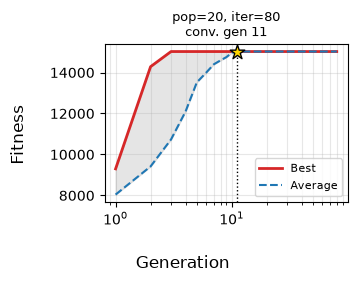

   pop_size  n_iter     final_avg    final_best  conv_gen
0        20      80  15024.042969  15024.042969        11


In [ ]:
def sga_trial_and_results( n_pop: int | list[int], n_iter: int | list[int], tolerance: float=0.001 ):
    """Runs the SGA for every (pop_size, n_iter) combination. """

    import itertools
    import pandas as pd

    pop_sizes   = n_pop  if isinstance(n_pop,  (list, tuple)) else [n_pop]
    iter_counts = n_iter if isinstance(n_iter, (list, tuple)) else [n_iter]

    n_rows, n_cols = len(pop_sizes), len(iter_counts)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.6 * n_cols, 2.8 * n_rows),
                             sharey=True, squeeze=False)   # squeeze=False keeps axes 2D even for 1 row/col

    pop_and_iter = itertools.product(enumerate(pop_sizes), enumerate(iter_counts))
    
    results = []

    for (r, n_pop), (c, n_iter) in pop_and_iter:

        # Hyperparameters: 
        # - Only n_pop and n_iter are adjustable.
        # - Others remain constant.
        sga_hparams = { 
            "n_pop": n_pop,
            "n_iter": n_iter,
            "c_prob": 0.85,
            "m_prob": 1/6, 
            "n_bits": 6,
        }

        ax = axes[r, c]
        
        avg_fit_data, best_fit_data = simple_genetic_algorithm( sga_hparams )
        gens = np.arange(1, n_iter + 1)          # start at 1: log(0) is undefined

        ax.plot(gens, best_fit_data, color="tab:red",  lw=2,            label="Best")
        ax.plot(gens, avg_fit_data,  color="tab:blue", lw=1.5, ls="--", label="Average")
        ax.fill_between(gens, avg_fit_data, best_fit_data, color="tab:gray", alpha=0.2)

        gen = find_convergence(avg_fit_data, best_fit_data, tolerance)
        if gen:
            ax.axvline(gen, color="black", ls=":", lw=1)
            ax.scatter(gen, best_fit_data[gen-1], marker="*", s=120, color="gold", edgecolor="black", zorder=5)

        if n_iter >= 20:              # log scale only helps for longer runs
            ax.set_xscale("log")
        ax.set_title(f"pop={n_pop}, iter={n_iter}\n" + (f"conv. gen {gen}" if gen else "not converged"),
                     fontsize=9)
        ax.grid(True, which="both", alpha=0.3)

        results.append({"pop_size": n_pop, "n_iter": n_iter,
                        "final_avg": avg_fit_data[-1], "final_best": best_fit_data[-1], "conv_gen": gen})

    axes[0, 0].legend(fontsize=8)
    fig.supxlabel("Generation")
    fig.supylabel("Fitness")
    fig.tight_layout()
    plt.show()
    return pd.DataFrame(results)
     

df = sga_trial_and_results( 20, 80 )

*Is the average and best fitness non-decreasing? Why / why not? Is this according to your expectation (knowing the specifics of the SGA implementation). Why / why not?*

**Answer:** Best and average are non-decreasing because survivor selection is deterministic $(\mu + \lambda)$ truncation, so the top individuals always survive.

### Testing with varied parameters

Show your results and comment on how the number of iterations and population size tend to affect the best and average fitness achieved after the SGA terminated. Comment on your findings and explain them.

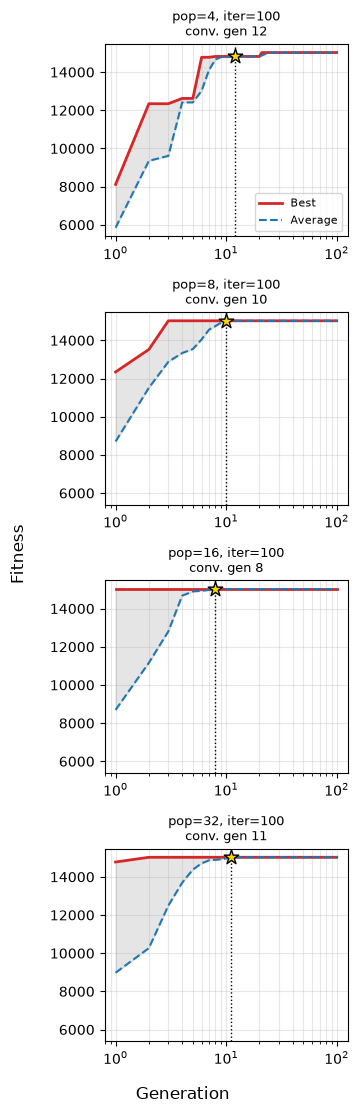

n_iter        100
pop_size         
4         15024.0
8         15024.0
16        15024.0
32        15024.0


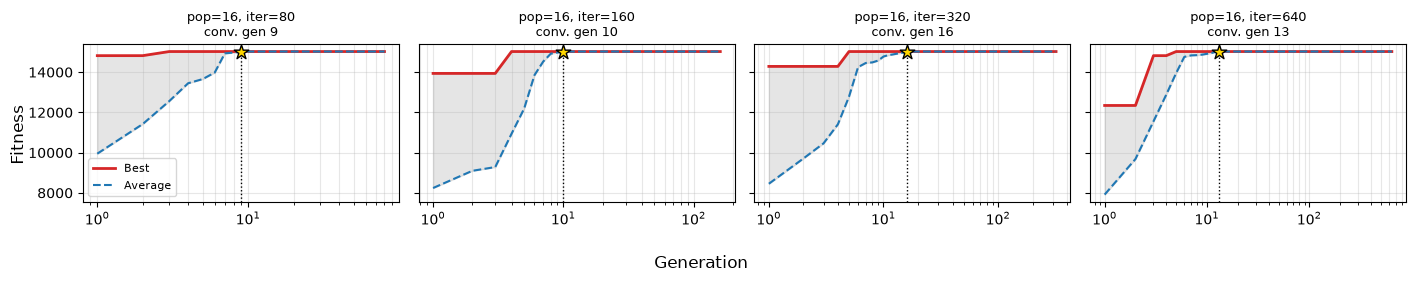

n_iter        80       160      320      640
pop_size                                    
16        15024.0  15024.0  15024.0  15024.0


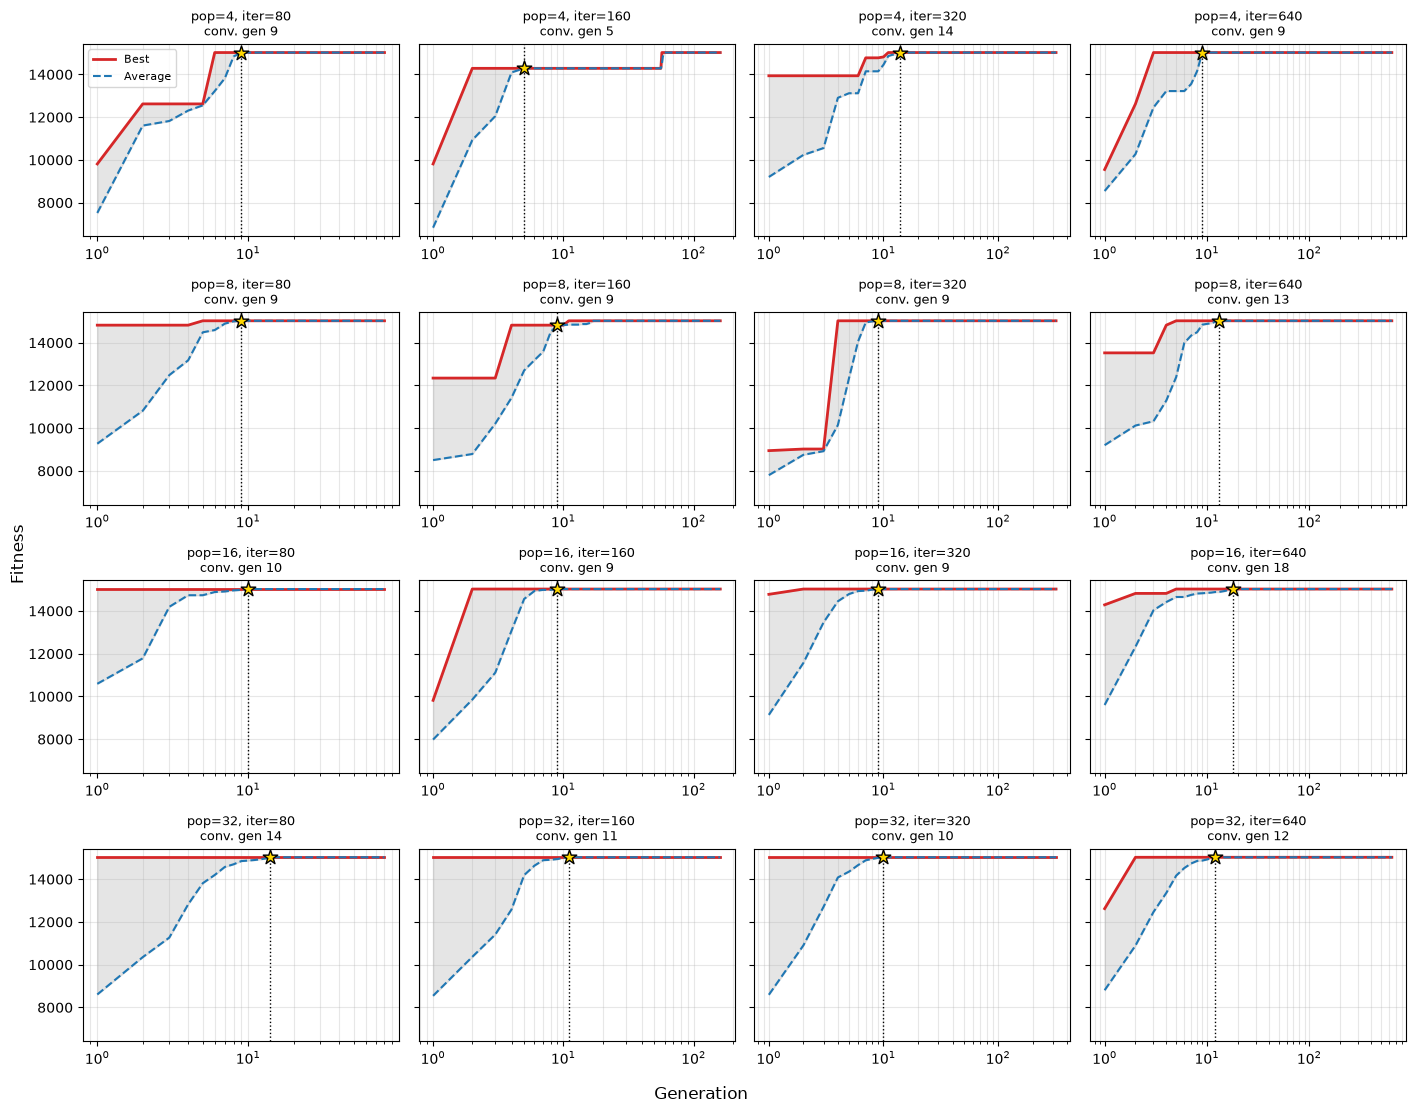

n_iter        80       160      320      640
pop_size                                    
4         15024.0  15024.0  15024.0  15024.0
8         15024.0  15024.0  15024.0  15024.0
16        15024.0  15024.0  15024.0  15024.0
32        15024.0  15024.0  15024.0  15024.0


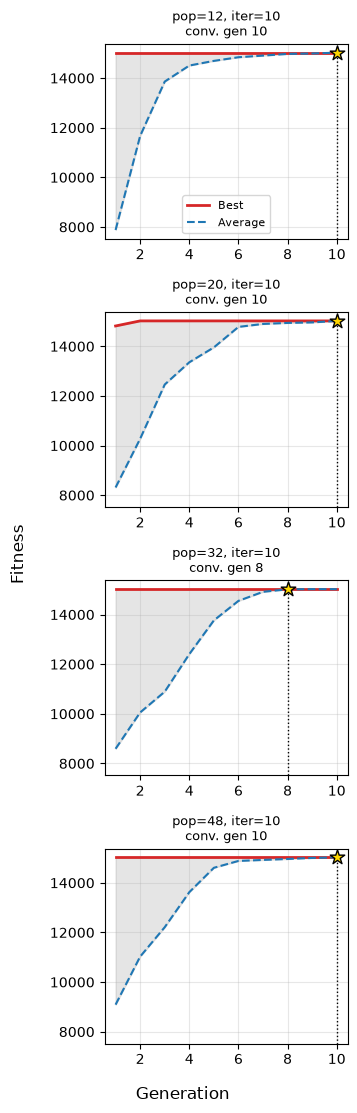

n_iter         10
pop_size         
12        15024.0
20        15024.0
32        15024.0
48        15024.0


In [59]:
def varied_trials():

    # Trial 1: Ppopulation size doubles and fixed number of iterations
    t1_n_pop, t1_n_iter = [4, 8, 16, 32], 100

    # Trial 2: Fixed population size and number of iterations doubles
    t2_n_pop, t2_n_iter  = 16, [80, 160, 320, 640]

    # Trial 3: Both population size and number of iterations double
    t3_n_pop, t3_n_iter =  [4, 8, 16, 32], [80, 160, 320, 640]

    # Trial 4: Number of iterations < population size 
    t4_n_pop,  t4_n_iter = [12, 20, 32, 48], 10

    trials = [ (t1_n_pop, t1_n_iter), 
               (t2_n_pop, t2_n_iter),
               (t3_n_pop, t3_n_iter), 
               (t4_n_pop,  t4_n_iter) 
            ]

    for n_pop, n_iter in trials:
        df = sga_trial_and_results( n_pop, n_iter )
        print( df.pivot(index="pop_size", columns="n_iter", values="final_avg").round(1) )
        

varied_trials()